# 06 · Simulación de producción

Proyecto Centinela (PSet 4). Cómo se construyeron los 26 lotes semanales de la partición de prueba, qué alteró la deriva inducida, cómo pasó el tráfico por la API y la trazabilidad de una predicción hasta el snapshot. **Solo lee** Snowflake (`CENTINELA.PRODUCCION`), MLflow y `docs/`; no cambia nada. Diseño: `docs/simulacion/diseno_deriva.md`.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(RAIZ / "src"), str(RAIZ / "monitoreo")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
# Paleta (skill de visualización): categórica en orden fijo; estados reservados para severidad.
MODELO, REGLAS, SIN_MODELO, GRIS = "#257de0", "#f47230", "#00b894", "#666666"
SEV = {"crítica": "#dc3c3d", "alta": "#f18a59", "media": "#fbb315", "baja": "#9c9c9c"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "figure.dpi": 110, "font.size": 9})
D1, D2 = 10, 14
def franjas(ax):
    ax.axvspan(D1 - .5, D2 - .5, color=GRIS, alpha=.07, lw=0); ax.axvspan(D2 - .5, 25.5, color=GRIS, alpha=.14, lw=0)
    y = ax.get_ylim()[1]
    ax.text(D1 - .3, y, "D1", va="top", fontsize=8, color=GRIS); ax.text(D2 - .3, y, "D1+D2", va="top", fontsize=8, color=GRIS)
from produccion import Snowflake, INICIO_SIM_SQL, FILTRO_SIM, N_LOTES, configurar_mlflow
sf = Snowflake()
print("Simulación vigente desde", sf.sql(f"SELECT {INICIO_SIM_SQL} AS i")["i"].iloc[0], "UTC")

Simulación vigente desde 2026-11-27 03:53:47.303000 UTC


## 1. Lotes y prevalencia

D1 quita el 70 % de las legítimas presenciales y conserva todos los fraudes: la prevalencia sube desde el lote 10 (por eso la AUC-PR de los lotes 10 a 13 no cae, o incluso sube).

,lote,desde,hasta,filas_originales,fraudes,prevalencia_original_pct,d1_legitimas_quitadas,d2_fraudes_camuflados,filas,prevalencia_pct,paso_llegada_target
0,0,2020-07-01,2020-07-07,20050,66,0.329,0,0,20050,0.329,2
1,1,2020-07-08,2020-07-14,19925,79,0.396,0,0,19925,0.396,3
2,2,2020-07-15,2020-07-21,19926,90,0.452,0,0,19926,0.452,4
3,3,2020-07-22,2020-07-28,19789,62,0.313,0,0,19789,0.313,5
4,4,2020-07-29,2020-08-04,19840,93,0.469,0,0,19840,0.469,6
5,5,2020-08-05,2020-08-11,19902,131,0.658,0,0,19902,0.658,7
6,6,2020-08-12,2020-08-18,19473,63,0.324,0,0,19473,0.324,8
7,7,2020-08-19,2020-08-25,19803,97,0.490,0,0,19803,0.490,9
8,8,2020-08-26,2020-09-01,19740,68,0.344,0,0,19740,0.344,10
9,9,2020-09-02,2020-09-08,16074,101,0.628,0,0,16074,0.628,11


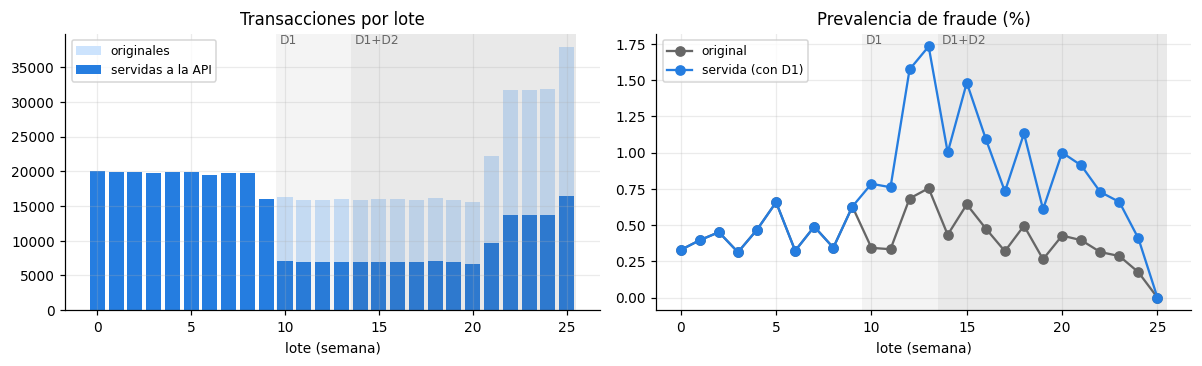

In [2]:
lotes = sf.sql("SELECT * FROM PRODUCCION.LOTES_RESUMEN ORDER BY LOTE")
display(lotes[["lote", "desde", "hasta", "filas_originales", "fraudes", "prevalencia_original_pct", "d1_legitimas_quitadas",
               "d2_fraudes_camuflados", "filas", "prevalencia_pct", "paso_llegada_target"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(lotes["lote"], lotes["filas_originales"], color="#cce3fd", label="originales")
ax[0].bar(lotes["lote"], lotes["filas"], color=MODELO, label="servidas a la API")
ax[0].set_title("Transacciones por lote"); ax[0].legend(fontsize=8); franjas(ax[0])
ax[1].plot(lotes["lote"], lotes["prevalencia_original_pct"], "o-", color=GRIS, label="original")
ax[1].plot(lotes["lote"], lotes["prevalencia_pct"], "o-", color=MODELO, label="servida (con D1)")
ax[1].set_title("Prevalencia de fraude (%)"); ax[1].legend(fontsize=8); franjas(ax[1])
for a in ax: a.set_xlabel("lote (semana)")
fig.tight_layout(); fig.savefig(RAIZ / "docs/simulacion/lotes_prevalencia.png", dpi=120); plt.show()

## 2. Deriva conceptual D2: fraudes camuflados

Desde el lote 14, la mitad de los fraudes toma un monto legítimo típico de su categoría y una hora diurna. Se comparan los valores originales con los servidos.

389 fraudes camuflados en los lotes 14 a 24
monto: mediana original 348.06 -> servida 55.53
% nocturnos (22-04): original 84.3 -> servido 0.0


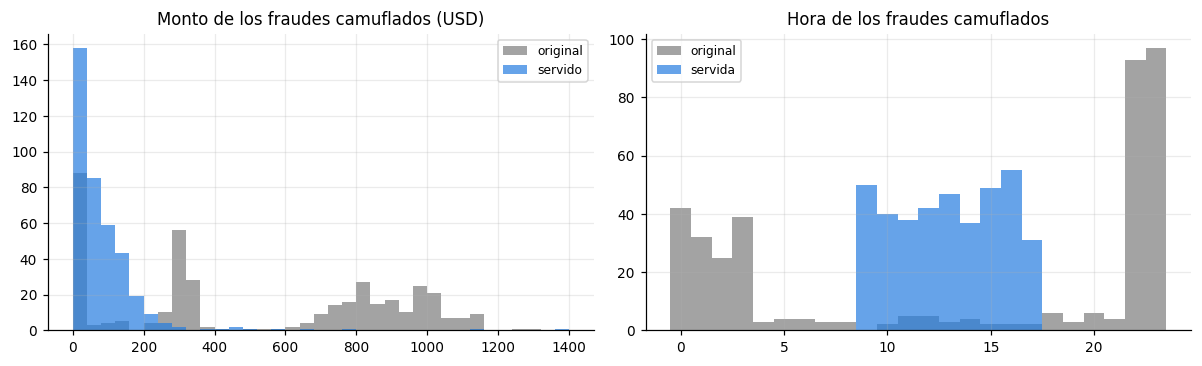

In [3]:
d2 = sf.sql("SELECT LOTE, AMT, AMT_ORIGINAL, HORA, HORA_ORIGINAL FROM PRODUCCION.LOTES WHERE ALTERADA_D2 AND LOTE < 26")
print(f"{len(d2)} fraudes camuflados en los lotes {d2.lote.min()} a {d2.lote.max()}")
print("monto: mediana original", round(d2.amt_original.median(), 2), "-> servida", round(d2.amt.median(), 2))
print("% nocturnos (22-04): original", round(100 * d2.hora_original.isin([22, 23, 0, 1, 2, 3]).mean(), 1), "-> servido", round(100 * d2.hora.isin([22, 23, 0, 1, 2, 3]).mean(), 1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
b = np.linspace(0, 1400, 36)
ax[0].hist(d2.amt_original.clip(upper=1400), b, color=GRIS, alpha=.6, label="original"); ax[0].hist(d2.amt.clip(upper=1400), b, color=MODELO, alpha=.7, label="servido")
ax[0].set_title("Monto de los fraudes camuflados (USD)"); ax[0].legend(fontsize=8)
h = np.arange(25) - .5
ax[1].hist(d2.hora_original, h, color=GRIS, alpha=.6, label="original"); ax[1].hist(d2.hora, h, color=MODELO, alpha=.7, label="servida")
ax[1].set_title("Hora de los fraudes camuflados"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(RAIZ / "docs/simulacion/deriva_d2_montos_horas.png", dpi=120); plt.show()

## 3. Tráfico por la API

200 transacciones por lote van una por una a `POST /predecir` (latencia online) y el resto, en bloques, a `POST /predecir_lote`. Cada una queda registrada en `PRODUCCION.PREDICCIONES`.

predicciones registradas: 338152 | transacciones distintas: 338152 | filas en LOTES: 338152
latencia online p50: mediana por lote 10.1 ms | p95 máximo 17.0 ms | 4xx 0 | 5xx 0


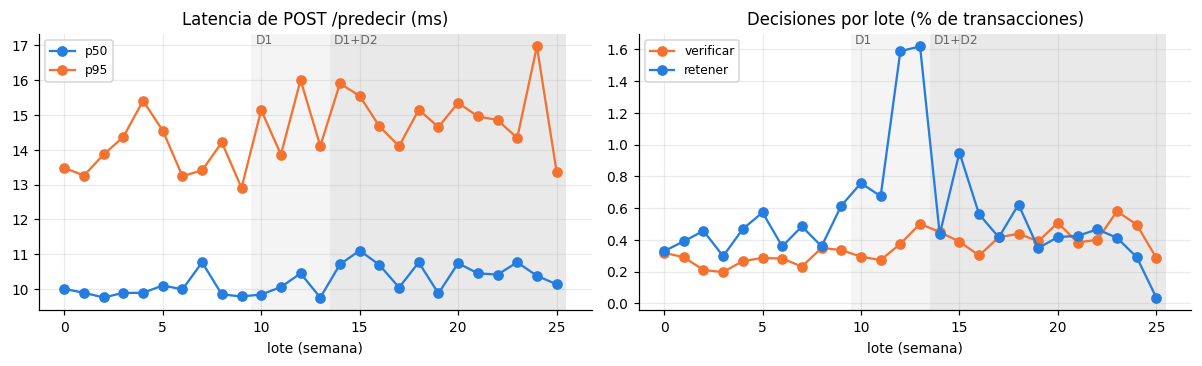

In [4]:
mon = pd.read_csv(RAIZ / "docs/monitoreo.csv")
sis = mon[mon.grupo == "sistema"].pivot_table(index="lote", columns="metrica", values="valor")
mod = mon[mon.grupo == "modelo"].pivot_table(index="lote", columns="metrica", values="valor")
reg = sf.sql(f"SELECT COUNT(*) AS n, COUNT(DISTINCT TRANS_NUM) AS d FROM PRODUCCION.PREDICCIONES WHERE {FILTRO_SIM} AND LOTE < {N_LOTES}")
print("predicciones registradas:", int(reg.n[0]), "| transacciones distintas:", int(reg.d[0]), "| filas en LOTES:", int(lotes.filas.sum()))
print("latencia online p50: mediana por lote", round(sis.latencia_online_p50_ms.median(), 1), "ms | p95 máximo", round(sis.latencia_online_p95_ms.max(), 1), "ms | 4xx", int(sis.errores_4xx.sum()), "| 5xx", int(sis.errores_5xx.sum()))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(sis.index, sis.latencia_online_p50_ms, "o-", color=MODELO, label="p50"); ax[0].plot(sis.index, sis.latencia_online_p95_ms, "o-", color=REGLAS, label="p95")
ax[0].set_title("Latencia de POST /predecir (ms)"); ax[0].legend(fontsize=8); franjas(ax[0])
ax[1].plot(mod.index, 100 * mod.tasa_verificar, "o-", color=REGLAS, label="verificar"); ax[1].plot(mod.index, 100 * mod.tasa_retener, "o-", color=MODELO, label="retener")
ax[1].set_title("Decisiones por lote (% de transacciones)"); ax[1].legend(fontsize=8); franjas(ax[1])
for a in ax: a.set_xlabel("lote (semana)")
fig.tight_layout(); fig.savefig(RAIZ / "docs/simulacion/trafico_api.png", dpi=120); plt.show()

## 4. Trazabilidad de una predicción

De una predicción de la simulación a la versión del modelo, su corrida en MLflow y el snapshot de datos con el que se entrenó.

In [5]:
import mlflow
from mlflow import MlflowClient
configurar_mlflow(); c = MlflowClient()
p = sf.sql(f"""SELECT p.ID_PREDICCION, p.TS_UTC, p.TRANS_NUM, p.LOTE, p.PROBABILIDAD, p.DECISION, p.MODELO_VERSION, p.RUN_ID,
                     t.IS_FRAUD, l.DATOS_SHA256 FROM PRODUCCION.PREDICCIONES p
              JOIN PRODUCCION.TARGETS_LLEGADOS t ON t.TRANS_NUM = p.TRANS_NUM AND t.LOTE = p.LOTE
              JOIN PRODUCCION.LOTES l ON l.TRANS_NUM = p.TRANS_NUM AND l.LOTE = p.LOTE
              WHERE p.{FILTRO_SIM.replace("TS_UTC", "p.TS_UTC")} AND p.LOTE = 22 AND t.IS_FRAUD = 1 AND p.DECISION = 'retener'
              ORDER BY p.TS_UTC LIMIT 1""").iloc[0]
run = c.get_run(p.run_id)
v = c.get_model_version("centinela-modelo", p.modelo_version)
traza = {"prediccion": p.id_prediccion, "trans_num": p.trans_num, "lote": int(p.lote), "probabilidad": round(float(p.probabilidad), 4),
         "decision": p.decision, "fraude_confirmado": int(p.is_fraud), "version": p.modelo_version, "run_id": p.run_id,
         "fase_de_la_corrida": run.data.tags.get("fase"), "motivo": run.data.tags.get("motivo"), "ventana": run.data.params.get("ventana"),
         "snapshot_sha256_de_la_corrida": run.data.params.get("datos_sha256"), "snapshot_sha256_del_lote": p.datos_sha256,
         "decision_de_promocion": v.tags.get("decision")}
print(json.dumps(traza, indent=2, ensure_ascii=False))
assert traza["snapshot_sha256_de_la_corrida"] == traza["snapshot_sha256_del_lote"]

{
  "prediccion": "99b2c605-edca-4e6b-bcd1-4902909df430",
  "trans_num": "1d419058b4efc747cf77bc51ef0c0fd1",
  "lote": 22,
  "probabilidad": 0.9982,
  "decision": "retener",
  "fraude_confirmado": 1,
  "version": "5",
  "run_id": "78983a0156364f048c5f2a761da29013",
  "fase_de_la_corrida": "reentrenamiento",
  "motivo": "desempeño",
  "ventana": "entrenamiento PSet 3 + lotes 0..18",
  "snapshot_sha256_de_la_corrida": "9be410f73fb8c090e7647fc27559665c28431d29a0652548d16d8b932d9e9bce",
  "snapshot_sha256_del_lote": "9be410f73fb8c090e7647fc27559665c28431d29a0652548d16d8b932d9e9bce",
  "decision_de_promocion": "aprobada"
}


**Conclusión.** Los 26 lotes pasaron completos por la API: hay una predicción registrada por cada transacción servida, y cada una se puede seguir hasta la versión, la corrida y el snapshot. Las cifras de latencia y decisiones de este notebook alimentan el monitoreo (`07_analisis_monitoreo.ipynb`).

In [6]:
sf.cerrar()